In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, f1_score, precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

C:\Users\potab\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df = pd.read_csv('creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [4]:
X = df.drop('Class', axis = 1)
y = df['Class']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

In [7]:
X_train_normal = X_train[y_train == 0]

C:\Users\potab\AppData\Local\Temp\ipykernel_23076\4175539354.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  X_train_normal = X_train[y_train == 0]


In [8]:
scaler = StandardScaler()
X_train_normal = scaler.fit_transform(X_train_normal)
X_test = scaler.transform(X_test)

In [9]:
print("Training data shape:", X_train_normal.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (227451, 30)
Testing data shape: (56962, 30)


In [10]:
input_dim = X_train_normal.shape[1]

autoencoder = keras.Sequential([
    keras.Input(shape = (input_dim, )),
    layers.Dense(16, activation = 'relu'),
    layers.Dense(8, activation = 'relu'),
    layers.Dense(16, activation = 'relu'),
    layers.Dense(input_dim, activation = 'linear')
])

In [11]:
autoencoder.compile(
    optimizer = 'adam',
    loss = 'mse',
    metrics = ['mae']
)

In [12]:
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs = 11,
    batch_size = 256,
    validation_split = 0.2
)

Epoch 1/11
711/711 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.7830 - mae: 0.5939 - val_loss: 0.6584 - val_mae: 0.5460
Epoch 2/11
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.6080 - mae: 0.5247 - val_loss: 0.5923 - val_mae: 0.5155
Epoch 3/11
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5583 - mae: 0.5052 - val_loss: 0.5544 - val_mae: 0.5001
Epoch 4/11
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5332 - mae: 0.4938 - val_loss: 0.5357 - val_mae: 0.4914
Epoch 5/11
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5186 - mae: 0.4857 - val_loss: 0.5251 - val_mae: 0.4845
Epoch 6/11
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5091 - mae: 0.4799 - val_loss: 0.5176 - val_mae: 0.4792
Epoch 7/11
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5026 - mae: 0.4747 - val_loss: 0.5129 - val_mae: 0.4754
Epoch 8/11
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.4983 - mae: 0.4719 - val_loss: 0.5086 - val_mae: 0.4725
Epoch 9/11
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - lo

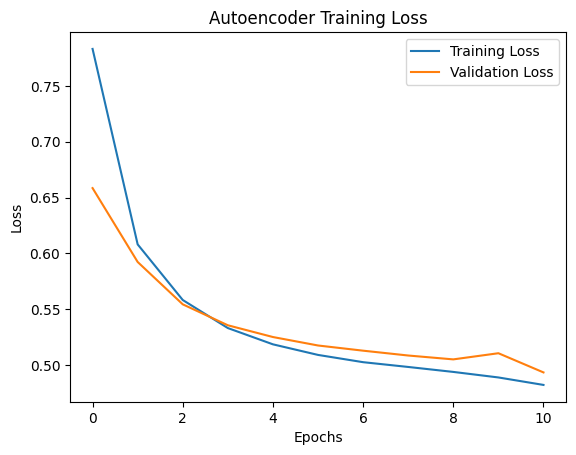

In [13]:
plt.plot(history.history['loss'], label = 'Training Loss')
plt.plot(history.history['val_loss'], label = 'Validation Loss')
plt.title('Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [14]:
X_train_pred = autoencoder.predict(X_train_normal)
X_test_pred = autoencoder.predict(X_test)

train_error = np.mean(np.square(X_train_normal - X_train_pred), axis = 1)
test_error = np.mean(np.square(X_test - X_test_pred), axis = 1)

threshold = np.percentile(train_error, 95)
print('Reconstruction Error Threshold = ', threshold)

7108/7108 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1781/1781 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step
Reconstruction Error Threshold =  0.9533791314609124


In [15]:
y_pred = (test_error > threshold).astype(int)

print("Predicted classes:")
print(y_pred[:20])

Predicted classes:
[1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0]


              precision    recall  f1-score   support

           0       1.00      0.95      0.97     56864
           1       0.03      0.84      0.05        98

    accuracy                           0.95     56962
   macro avg       0.51      0.89      0.51     56962
weighted avg       1.00      0.95      0.97     56962



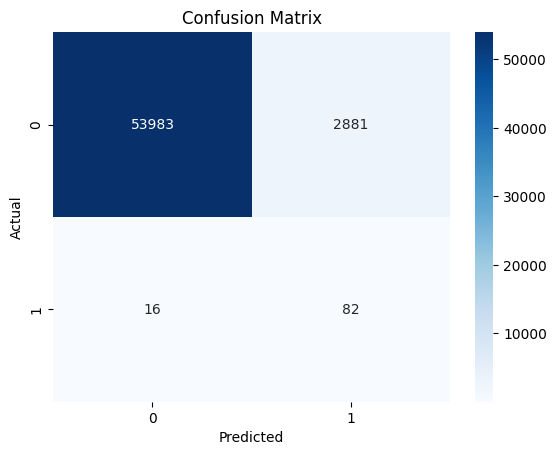

In [17]:
# Classification Report
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()